#### Objective
This project aims to perform **Customer Segmentation** using the **K-Means Clustering algorithm**, an unsupervised machine learning method, based on credit card usage data from **Bank Berlian** over the past six months.
The objective is to group customers based on their credit card usage patterns and financial behavior. By identifying distinct customer segments, the marketing team can better understand the **characteristics and behavior of each customer group** and develop more effective, targeted marketing strategies.

# 1. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr, spearmanr

from feature_engine.outliers import Winsorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score
)

import joblib
import os

# 2. Data Loading

In [ ]:
df = pd.read_csv('data_cc.csv')

df.head(10)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,2754,2.907271,0.200000,53.00,53.0,0.00,0.0,0.100000,0.100000,0.000000,0.0,0,1,1000.0,239.669232,72.466408,0.000000,10
1,3038,31.870629,0.818182,192.92,139.7,53.22,0.0,0.166667,0.083333,0.083333,0.0,0,2,5500.0,834.627595,92.360868,0.090909,12
2,4894,115.467669,0.545455,354.00,354.0,0.00,0.0,0.166667,0.166667,0.000000,0.0,0,2,16500.0,4555.965464,211.042680,0.000000,12
3,8312,2817.590920,1.000000,37.92,0.0,37.92,0.0,0.166667,0.000000,0.166667,0.0,0,2,3000.0,755.313452,1167.316335,0.000000,12
4,5114,158.657744,0.909091,752.00,752.0,0.00,0.0,0.250000,0.250000,0.000000,0.0,0,4,2500.0,865.171658,161.710712,0.000000,12
5,7580,135.037323,1.000000,270.00,0.0,270.00,0.0,0.272727,0.000000,0.181818,0.0,0,3,3300.0,1760.310579,1471.250082,1.000000,11
6,1626,771.773362,1.000000,750.00,250.0,500.00,0.0,0.333333,0.083333,0.250000,0.0,0,5,4000.0,204.167996,260.332459,0.000000,12
7,1970,16.068323,0.636364,182.80,79.0,103.80,0.0,0.333333,0.083333,0.250000,0.0,0,4,1200.0,294.668739,108.486655,0.571429,12
8,2186,160.681189,0.909091,993.50,896.0,97.50,0.0,0.333333,0.166667,0.166667,0.0,0,9,6500.0,980.963861,140.519148,0.090909,12
9,4516,1733.972492,1.000000,147.96,0.0,147.96,0.0,0.333333,0.000000,0.333333,0.0,0,8,1900.0,525.331558,670.323657,0.000000,12


In [3]:
df.tail(10)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
4465,4024,3948.776884,1.000000,0.00,0.00,0.00,5291.215227,0.000000,0.000000,0.000000,0.500000,17,0,4000.0,4576.567640,1819.139749,0.083333,12
4466,4614,7698.663007,1.000000,673.15,574.28,98.87,6076.961711,0.833333,0.250000,0.750000,0.500000,8,14,12000.0,1907.169830,2144.047631,0.000000,12
4467,2882,15155.532860,1.000000,717.24,717.24,0.00,4718.274895,1.000000,1.000000,0.000000,0.500000,7,24,18000.0,4002.194556,3843.924668,0.000000,12
4468,5218,4373.439331,0.888889,1959.04,1570.04,389.00,5124.126997,0.666667,0.444444,0.555556,0.555556,6,12,7000.0,820.851704,1409.800552,0.000000,9
4469,82,5983.285834,1.000000,4170.04,4020.04,150.00,2359.135053,0.750000,0.750000,0.416667,0.583333,17,23,7000.0,2974.801874,3232.760835,0.000000,12
4470,7682,2182.752161,1.000000,3216.97,2360.30,856.67,5594.061996,1.000000,0.666667,1.000000,0.583333,17,51,10000.0,7573.546529,501.711259,0.250000,12
4471,5192,13968.479570,1.000000,281.71,8.90,272.81,2710.679764,0.416667,0.083333,0.333333,0.666667,12,9,18500.0,3464.441992,3360.086085,0.000000,12
4472,5878,381.341657,1.000000,78.00,0.00,78.00,934.808869,1.000000,0.000000,0.833333,0.666667,16,6,1000.0,143.118373,85.152441,0.000000,6
4473,1300,3619.986054,1.000000,0.00,0.00,0.00,1483.636800,0.000000,0.000000,0.000000,0.750000,17,0,13000.0,942.812569,920.525945,0.000000,12
4474,2152,1420.727073,1.000000,0.00,0.00,0.00,311.804499,0.000000,0.000000,0.000000,0.900000,9,0,1500.0,506.765033,449.179818,0.000000,10


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4475 entries, 0 to 4474
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           4475 non-null   int64  
 1   BALANCE                           4475 non-null   float64
 2   BALANCE_FREQUENCY                 4475 non-null   float64
 3   PURCHASES                         4475 non-null   float64
 4   ONEOFF_PURCHASES                  4475 non-null   float64
 5   INSTALLMENTS_PURCHASES            4475 non-null   float64
 6   CASH_ADVANCE                      4475 non-null   float64
 7   PURCHASES_FREQUENCY               4475 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        4475 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  4475 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            4475 non-null   float64
 11  CASH_ADVANCE_TRX                  4475 non-null   int64  
 12  PURCHA

In [5]:
missing_values = df.isnull().sum()
print(missing_values)

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    158
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64


In [ ]:
print(
    "Duplicates: ", df.duplicated().sum()
)

Jumlah Duplikat:  0


##### Data Overview

After retrieving the dataset using the SQL query above, the data is saved as a **CSV file** and uploaded into the notebook for further analysis.

- The **first 10 rows and last 10 rows** of the dataset are displayed to provide an initial overview of the data.
- The dataset consists of **4,474 customers and 18 columns**, where each row represents the credit card usage behavior of an individual customer.
- **Missing values** are identified in the `CREDIT_LIMIT` and `MINIMUM_PAYMENTS` columns. These missing values will be handled using **median imputation**.
- **No duplicate records** are found in the dataset.


# 3. Exploratory Data Analysis (EDA)

#### 1. Is there a relationship between `TENURE` and the variables `PURCHASES`, `BALANCE`, and `PAYMENTS`?Conduct statistical tests and create visualizations to examine the relationships between these variables. Based on the findings, provide business recommendations for the marketing team.


In [7]:
features = ['TENURE', 'PURCHASES', 'BALANCE', 'PAYMENTS']

df[features].corr()

,TENURE,PURCHASES,BALANCE,PAYMENTS
TENURE,1.000000,0.085754,0.072629,0.098036
PURCHASES,0.085754,1.000000,0.175823,0.593112
BALANCE,0.072629,0.175823,1.000000,0.330390
PAYMENTS,0.098036,0.593112,0.330390,1.000000


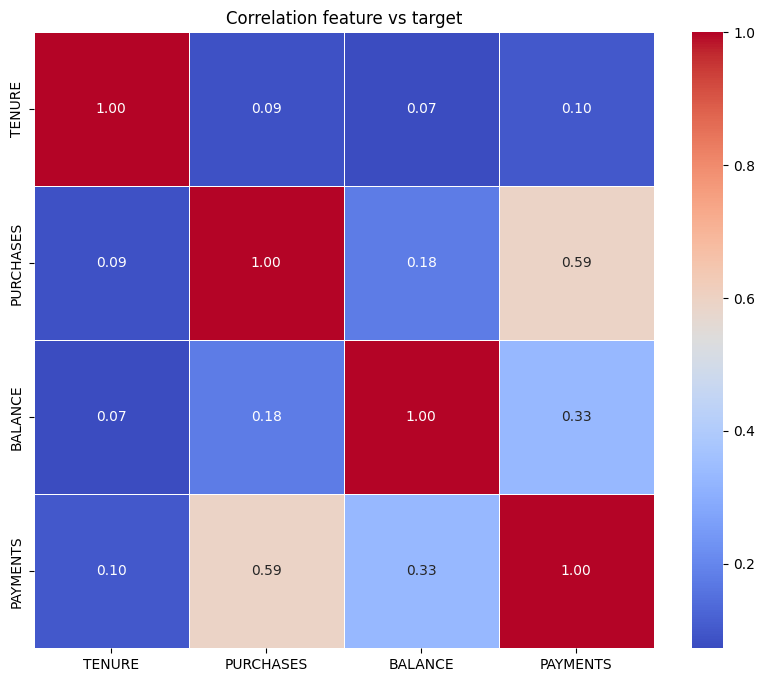

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm', fmt = '.2f', linewidths=0.5)

plt.title('Correlation feature vs target')
plt.show()

- The relationship between `TENURE` and `PURCHASES`, `BALANCE`, and `PAYMENTS` shows a **positive but weak correlation**.
- This indicates that **customer tenure alone is not a strong factor in explaining customer transaction behavior**.

#### 2. Do customers with higher `CREDIT_LIMIT` tend to make purchases more frequently?Conduct an analysis to examine the relationship between `CREDIT_LIMIT` and `PURCHASES_FREQUENCY`. Create a visualization to illustrate this relationship and provide business recommendations for the marketing team based on the findings.

In [9]:
credit_limit = df[["CREDIT_LIMIT", "PURCHASES_FREQUENCY"]].dropna()

pearson_credit, pearson_p_value = pearsonr(credit_limit["CREDIT_LIMIT"], credit_limit["PURCHASES_FREQUENCY"])
spearman_credit, spearman_p_value = spearmanr(credit_limit["CREDIT_LIMIT"], credit_limit["PURCHASES_FREQUENCY"])

print(f"Pearson correlation coefficient: {pearson_credit:.4f}, p-value: {pearson_p_value:.4f}")
print(f"Spearman correlation coefficient: {spearman_credit:.4f}, p-value: {spearman_p_value:.4f}")

Pearson correlation coefficient: 0.1328, p-value: 0.0000
Spearman correlation coefficient: 0.1227, p-value: 0.0000


- There is a **positive but weak correlation** between `CREDIT_LIMIT` and `PURCHASES_FREQUENCY`.
- This indicates that customers with higher credit limits tend to make purchases more frequently. However, the relationship is relatively weak, suggesting that **credit limit alone is not a strong predictor of purchase frequency**.


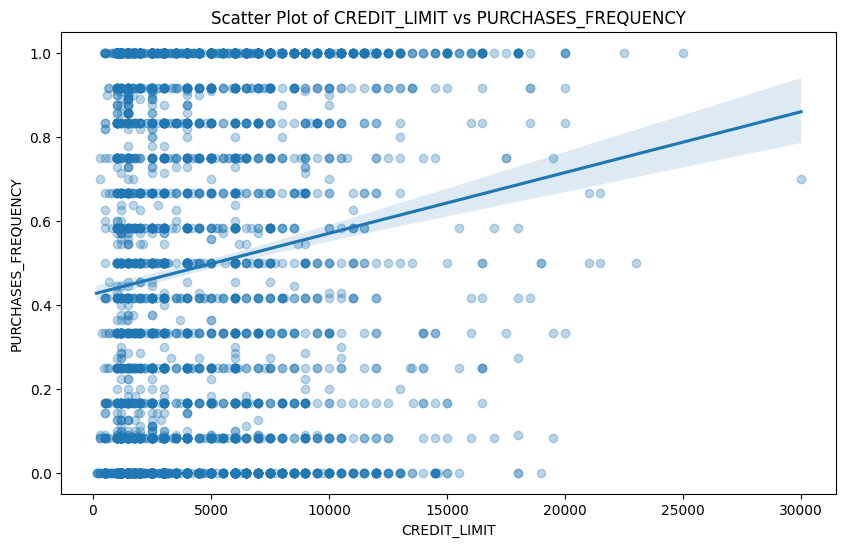

In [10]:
plt.figure(figsize=(10, 6))
sns.regplot(data=credit_limit, x="CREDIT_LIMIT", y="PURCHASES_FREQUENCY", scatter_kws={'alpha': 0.3})
plt.title("Scatter Plot of CREDIT_LIMIT vs PURCHASES_FREQUENCY")
plt.xlabel("CREDIT_LIMIT")
plt.ylabel("PURCHASES_FREQUENCY")
plt.show()

- Based on the scatterplot above, some customers with **lower credit limits** also tend to have **higher purchase frequencies**.
- The data points on the left side of the scatterplot appear relatively **dense**, indicating that many customers with lower credit limits also make purchases frequently.
- This suggests that **a higher credit limit does not necessarily lead to more frequent purchases**, as customers with lower credit limits can also demonstrate high purchasing activity.


# 4. Feature Engineering

##### 1. Cardinality Check

In [11]:
cardinality = pd.DataFrame({
    "Features" : df.columns,
    "Cardinality" : [df[col].nunique() for col in df.columns]
})

cardinality.sort_values("Cardinality")

,Features,Cardinality
17,TENURE,7
2,BALANCE_FREQUENCY,42
8,ONEOFF_PURCHASES_FREQUENCY,44
10,CASH_ADVANCE_FREQUENCY,46
7,PURCHASES_FREQUENCY,47
16,PRC_FULL_PAYMENT,47
9,PURCHASES_INSTALLMENTS_FREQUENCY,47
11,CASH_ADVANCE_TRX,55
12,PURCHASES_TRX,147
13,CREDIT_LIMIT,153


#### 2. Feature Selection

In [12]:
df_model = df.copy()
df_model = df_model.drop(columns=["CREDIT_LIMIT_GROUP"])

KeyError: "['CREDIT_LIMIT_GROUP'] not found in axis"

Drop the columns previously created for Exploratory Data Analysis (EDA).


#### 3. Handling Missing Values

In [13]:
df_model = df[features].copy()

In [14]:
imputer = SimpleImputer(strategy='median')

imputed_array = imputer.fit_transform(df_model)
imputed = pd.DataFrame(
    imputed_array,
    columns= df_model.columns,
    index= df_model.index)

Missing values are handled using **SimpleImputer** with the **median strategy**.


#### 4. Handling Outlier

In [15]:
skewness = df_model.skew()

skewness

TENURE      -2.932822
PURCHASES    8.987052
BALANCE      2.456621
PAYMENTS     6.040773
dtype: float64

Based on the dataset, several columns exhibit **high skewness**, indicating that their distributions are not symmetrical.


In [16]:
winsorizer = Winsorizer(
    capping_method= 'quantiles' ,
    tail='both' ,
    fold= 0.01 ,
    variables= features
)

winsorizerd = winsorizer.fit_transform(imputed)

Outliers are handled using **Winsorizer** with the **quantile-based method**.


#### 5. Feature Scaling

In [17]:
scaler = StandardScaler()

scaled = scaler.fit_transform(winsorizerd)

Feature scaling is performed using **StandardScaler** to standardize the numerical features.


#### 6. PCA

In [18]:
pca = PCA()
pca.fit(scaled)



PCA()

In [19]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

print(cumulative_variance)

[0.43678261 0.67638508 0.88926085 1.        ]


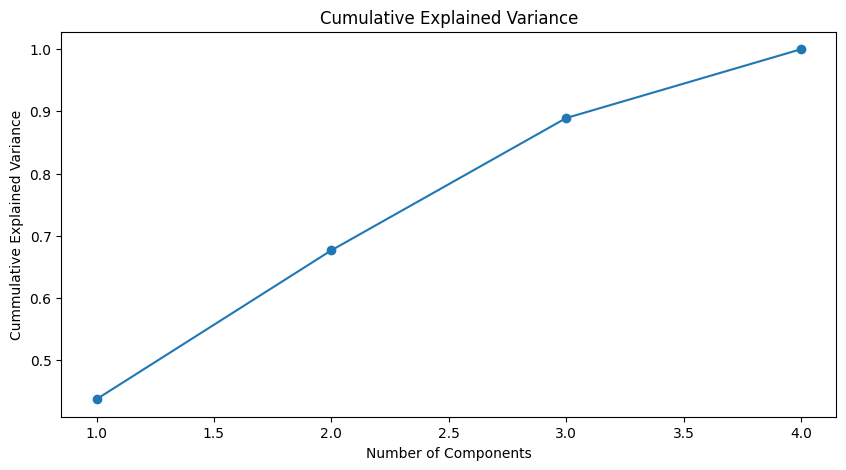

In [20]:
plt.figure(figsize=(10,5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Components')
plt.ylabel('Cummulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.show()

In [21]:
cumsum = np.cumsum(pca.explained_variance_ratio_)
num_features = np.argmax(cumsum >= 0.95) + 1
num_features

4

In [22]:
pca = PCA(n_components=0.95)
pca.fit(scaled)

scaled_pca = pca.transform(scaled)

Using **Principal Component Analysis (PCA)**, the dimensionality of the dataset is reduced from **17 original features to 4 principal components**, which will be used for further modeling.


# 7. Find Optimal Number of Clusters

#### 1. Elbow Method

In [24]:
inertia = []

k_range = range(2, 9)

for k in k_range :
   kmeans_model = KMeans(
      n_clusters= k,
      random_state=42,
      n_init=20
   )

   kmeans_model.fit(scaled_pca)

   inertia.append(kmeans_model.inertia_)


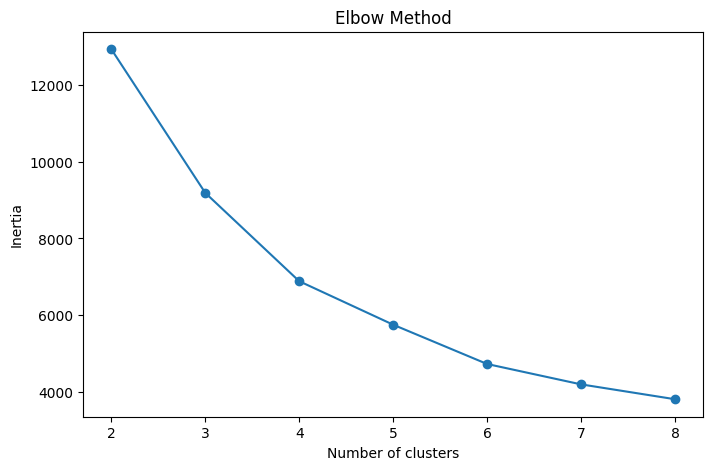

In [25]:
plt.figure(figsize=(8,5))

plt.plot(
    k_range,
    inertia,
    marker="o"
)

plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_range))
plt.show()



##### Elbow Method Analysis

- The **Elbow Method** is used to observe changes in inertia as the number of clusters increases.
- **Inertia** represents the total squared distance between data points and their assigned cluster centroids. Lower inertia indicates more compact clusters. However, increasing the number of clusters also increases model complexity.
- Based on the Elbow Method, a **significant decrease in inertia** occurs between 2 and 3 clusters, followed by smaller improvements as the number of clusters increases.
- Therefore, the optimal number of clusters will be determined by combining the **Elbow Method** with the **Silhouette Score**.


#### 2. Silhouette Score

In [27]:
silhouette_scores = []

for k in k_range:
    kmeans_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = kmeans_model.fit_predict(scaled_pca)
    score = silhouette_score(scaled_pca,labels)
    silhouette_scores.append(score)


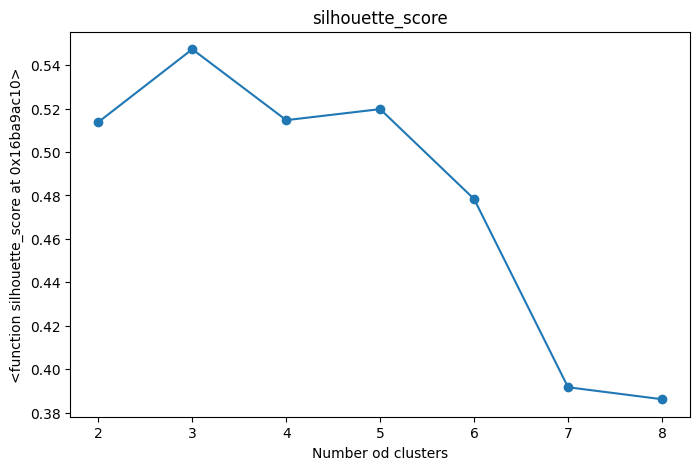

In [29]:
plt.figure(figsize=(8,5))

plt.plot(
    k_range,
    silhouette_scores,
    marker="o"
)
plt.xlabel("Number od clusters")
plt.ylabel(silhouette_score)
plt.title("silhouette_score")
plt.xticks(list(k_range))
plt.show()

##### Silhouette Score Analysis

- The **highest Silhouette Score** is achieved at **k=3**, with a score of approximately **0.55**.
- Although the score is not close to 1, **k=3 provides the best cluster separation** compared to the other numbers of clusters tested.
- Therefore, **k=3 is selected as the primary candidate** for the K-Means Clustering model.


#### 3. Penentuan Jumlah Cluster Terbaik

In [31]:
evaluation_df = pd.DataFrame({
    "K":list(k_range),
    "inertia": inertia,
    "silhouette_score": silhouette_scores
})

evaluation_df

,K,inertia,silhouette_score
0,2,12931.455501,0.513765
1,3,9187.293011,0.547309
2,4,6885.111053,0.514658
3,5,5751.690168,0.519733
4,6,4727.720700,0.478327
5,7,4196.708499,0.391693
6,8,3809.567578,0.386178


##### Final Model Selection

- Based on the **Silhouette Score**, **K=3** achieves the highest score compared to the other cluster configurations.
- The **Elbow Method** also supports selecting K=3, as the reduction in inertia becomes less significant beyond this point.
- Therefore, **K=3 is selected as the final K-Means Clustering model** because it provides good cluster separation while maintaining a relatively small number of clusters, making the results easier to interpret and understand.

#### 4. Evaluasi Cluster

In [34]:
best_k = 3

best_model_temp = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)
best_model_temp


KMeans(n_clusters=3, n_init=20, random_state=42)

# 8.Model Definition

#### K-Means Clustering

**K-Means** is an **unsupervised learning algorithm** that groups data points into clusters based on their proximity to cluster centroids.

The algorithm works through the following steps:
1. Determine the optimal number of clusters (**K**).
2. Initialize the cluster centroids.
3. Assign each observation to the nearest centroid.
4. Recalculate the centroids based on the assigned observations.
5. Repeat the process until the centroids stabilize or the stopping criteria are met.

**K-Means Clustering** is selected because it is well-suited for **customer segmentation** and produces results that are relatively easy to interpret.


# 9. Model Training

In [36]:
best_k = 3

kemans_model_fin = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=20,
    max_iter=500
)

kemans_model_fin.fit(scaled_pca)

KMeans(max_iter=500, n_clusters=3, n_init=20)

In [37]:
cluster_labels = kemans_model_fin.labels_

cluster_labels[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [38]:
df_cluster = df.copy()

df_cluster["Cluster"] = cluster_labels

df_cluster.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster
0,2754,2.907271,0.200000,53.00,53.0,0.00,0.0,0.100000,0.100000,0.000000,0.0,0,1,1000.0,239.669232,72.466408,0.000000,10,0
1,3038,31.870629,0.818182,192.92,139.7,53.22,0.0,0.166667,0.083333,0.083333,0.0,0,2,5500.0,834.627595,92.360868,0.090909,12,0
2,4894,115.467669,0.545455,354.00,354.0,0.00,0.0,0.166667,0.166667,0.000000,0.0,0,2,16500.0,4555.965464,211.042680,0.000000,12,0
3,8312,2817.590920,1.000000,37.92,0.0,37.92,0.0,0.166667,0.000000,0.166667,0.0,0,2,3000.0,755.313452,1167.316335,0.000000,12,0
4,5114,158.657744,0.909091,752.00,752.0,0.00,0.0,0.250000,0.250000,0.000000,0.0,0,4,2500.0,865.171658,161.710712,0.000000,12,0


# 10. Model Evaluation

#### 1. Cluster Visualization in 2D Space


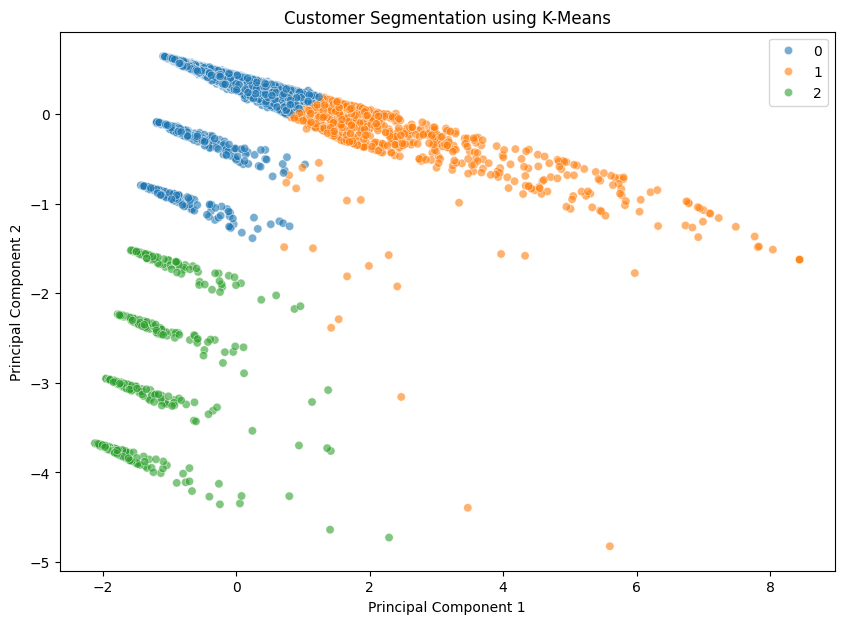

In [39]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=scaled_pca[:, 0],
    y=scaled_pca[:, 1],
    hue=cluster_labels,
    palette="tab10",
    alpha=0.6
)

plt.title(
    "Customer Segmentation using K-Means"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

- The data points across clusters are **relatively well-separated and clearly distinguishable**.
- Based on the visualization of **PC1 and PC2**, **Cluster 2** appears relatively separated from Clusters 0 and 1, while **Clusters 0 and 1** have some overlapping or closely positioned areas.
- This indicates that there are **differences in characteristics among customer segments**, although some customers may share similar behavioral patterns across clusters.


#### 2. Analysis of Each Cluster's Characteristics


In [ ]:
cluster_profile = (
    df_cluster
    .drop(columns=["CUST_ID"])
    .groupby("Cluster")
    .mean()
    .round(2)
)

cluster_profile

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,1076.97,0.87,599.13,302.35,297.24,596.79,0.46,0.16,0.35,0.11,2.47,10.76,3815.93,1042.47,677.80,0.16,11.89
1,4446.17,0.97,3451.89,2268.61,1183.39,2739.99,0.66,0.44,0.52,0.21,6.43,38.97,9014.18,5861.98,1992.45,0.16,11.93
2,1017.11,0.79,433.67,278.02,155.66,1326.86,0.42,0.14,0.27,0.21,4.21,6.00,2830.94,776.52,404.60,0.17,7.43


In [42]:
cluster_size = df_cluster["Cluster"].value_counts().sort_index()

cluster_percentage = (
    df_cluster["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .round(2)
)

cluster_summary = pd.DataFrame({
    "Jumalh Customer": cluster_size,
    "Percentage" : cluster_percentage
})
cluster_summary

,Jumalh Customer,Percentage
Cluster,,
0,3436,0.77
1,656,0.15
2,383,0.09


##### Cluster 0 Characteristics

- **Cluster 0** consists of approximately **77% of customers (3,436 users)**, making it the largest cluster.
- Customers in this cluster have **relatively low purchase activity** and a **medium credit limit** compared to the other clusters.
- This cluster consists of **long-tenured customers**, indicating that most users have been with the bank for a relatively long time.

##### Cluster 1 Characteristics

- **Cluster 1** consists of approximately **15% of customers (656 users)**.
- Customers in this cluster have the **highest purchase activity** compared to the other clusters.
- This cluster also has a **balance approximately four times higher** than the other clusters.
- Customers in this cluster have the **longest tenure**, indicating that they are the bank's most established customers.

##### Cluster 2 Characteristics

- **Cluster 2** consists of approximately **9% of customers (383 users)**, making it the smallest cluster.
- Customers in this cluster have the **lowest purchase activity** compared to the other clusters.
- However, they show a **high preference for cash advances**, with cash advance levels similar to those of Cluster 1.
- This cluster consists of customers with the **shortest tenure**, indicating that they are relatively new customers compared to the other clusters.





#### 3. Cluster Profiling

In [45]:
segment_names = {
    0 : "Medium Purchase / Medium Limit",
    1 : "High Purchase / High Limit",
    2 : "Low Purchase / Cash Oriented"
}

df_cluster["Customer_Segment"] = (
    df_cluster["Cluster"]
    .map(segment_names)
)

df_cluster[
    ["CUST_ID",
     "Cluster",
     "Customer_Segment"]
].head(50)


,CUST_ID,Cluster,Customer_Segment
0,2754,0,Medium Purchase / Medium Limit
1,3038,0,Medium Purchase / Medium Limit
2,4894,0,Medium Purchase / Medium Limit
3,8312,0,Medium Purchase / Medium Limit
4,5114,0,Medium Purchase / Medium Limit
5,7580,0,Medium Purchase / Medium Limit
6,1626,0,Medium Purchase / Medium Limit
7,1970,0,Medium Purchase / Medium Limit
8,2186,0,Medium Purchase / Medium Limit
9,4516,0,Medium Purchase / Medium Limit


#### 4. Business Recommendations for Each Cluster

##### Cluster 0 - Medium Purchase / Medium Limit

Customers in this cluster have **relatively low purchase activity and purchase frequency**, despite having a relatively long tenure with the bank.

**Business Recommendations:**
1. Launch **targeted marketing campaigns** to encourage customers to use their credit cards more frequently for purchases.
2. Offer **cashback or reward programs** for specific transactions, such as retail purchases, to increase customer engagement and transaction frequency.

##### Cluster 1 - High Purchase / High Limit

Customers in this cluster have the **highest purchase activity and purchase frequency**, making them a valuable customer segment for the bank.

**Business Recommendations:**
1. Implement **loyalty programs** to reward frequent transactions and encourage customer retention.
2. Provide **premium benefits**, such as exclusive promotions, special rewards, or additional privileges.
3. Strengthen **customer relationship management** to maintain satisfaction and loyalty, as this cluster contributes significantly to transaction activity.

##### Cluster 2 - Low Purchase / Cash Oriented

Customers in this cluster have the **shortest tenure and lowest purchase activity**, but show relatively high cash advance usage.

**Business Recommendations:**
1. Launch **targeted campaigns** to encourage customers to increase their credit card usage for purchases.
2. Offer **cashback or rewards** for specific transactions, such as retail purchases, to stimulate purchasing activity.
3. **Reduce customer dependence on cash advances** by increasing awareness of the benefits of using credit cards for direct purchases.



#### 5. Strengths and Weaknesses of The Model

##### Advantages of K-Means

1. **Simple and easy to understand**, making the clustering results relatively easy to interpret.
2. **Efficient clustering process**, allowing the algorithm to handle large datasets with relatively low computational costs.
3. **PCA helps reduce data dimensionality** before clustering, improving computational efficiency and reducing feature complexity.

##### Disadvantages of K-Means

1. **Requires a predefined number of clusters (K)** before running the algorithm.
2. **Sensitive to outliers**, as extreme values can significantly affect cluster centroids.
3. **Requires feature scaling**, since K-Means is a distance-based algorithm and features with larger scales can dominate the clustering process.



# 11. Model Saving

In [46]:
os.makedirs(
    "model_artifacts",
    exist_ok=True
)

In [48]:
joblib.dump(
    imputer,
    "model_artifacts/imputer.joblib"
)

joblib.dump(
    winsorizer,
    "model_artifacts/winsorizer.joblib"
)

joblib.dump(
    scaler,
    "model_artifacts/scaler.joblib"
)

joblib.dump(
    pca,
    "model_artifacts/pca.joblib"
)

joblib.dump(
    kemans_model_fin,
    "model_artifacts/kmeans.joblib"
)

['model_artifacts/kmeans.joblib']

# 12. Conclusion

####  EDA Findings

- Based on the **Exploratory Data Analysis (EDA)**, there is a **positive but weak correlation** between `TENURE` and `PURCHASES`, `BALANCE`, and `PAYMENTS`. Among these variables, the **strongest Spearman correlation** is observed between `TENURE` and `PAYMENTS`.

- Furthermore, the relationship between `CREDIT_LIMIT` and `PURCHASES_FREQUENCY` also shows a **positive correlation**. Customers with higher credit limits tend to have slightly higher purchase frequencies. However, the relationship is relatively weak, indicating that **credit limit is not the only factor influencing purchase frequency**.

#### Modeling Prosecces and Evaluation

- During the modeling process, the data undergoes several preprocessing steps, including **missing value handling using SimpleImputer, outlier handling using Winsorizer, feature scaling, Principal Component Analysis (PCA), and K-Means Clustering**.
- The optimal number of clusters is determined using the **Elbow Method** and **Silhouette Score**.
- Based on the evaluation results, **K=3 is selected as the final number of clusters** because it provides the best clustering performance while maintaining a relatively small number of clusters, making the model less complex and easier to interpret.


#### Summary of Clusters's Characteristics

#### Customer Segmentation Results

##### Cluster 0 - Medium Purchase / Medium Limit

- **Cluster 0** consists of approximately **77% of customers (3,436 users)**, making it the largest customer segment.
- Customers in this cluster have **relatively low purchase activity** and a **medium credit limit** compared to the other clusters.
- This cluster consists of **long-tenured customers**, indicating that they have been using the bank's services for a relatively long time.

##### Cluster 1 - High Purchase / High Limit

- **Cluster 1** consists of approximately **15% of customers (656 users)**.
- Customers in this cluster have the **highest purchase activity** compared to the other clusters.
- Their average **balance is approximately four times higher** than that of customers in the other clusters.
- This cluster has the **longest customer tenure**, indicating that these customers have maintained their relationship with the bank for the longest period.

##### Cluster 2 - Low Purchase / Cash Oriented

- **Cluster 2** consists of approximately **9% of customers (383 users)**, making it the smallest customer segment.
- Customers in this cluster have the **lowest purchase activity** compared to the other clusters.
- However, they show **relatively high cash advance usage**, with cash advance levels similar to those of Cluster 1.
- This cluster has the **shortest customer tenure**, indicating that its members are relatively new customers compared to the other clusters.


#### Business Recommendations

#### Business Recommendations for Each Cluster

##### Cluster 0 - Medium Purchase / Medium Limit

**Business Recommendations:**
1. Launch **targeted marketing campaigns** to encourage customers to use their credit cards more frequently for purchases.
2. Offer **cashback or reward programs** for specific transactions, such as retail purchases, to increase customer engagement and transaction frequency.

##### Cluster 1 - High Purchase / High Limit

**Business Recommendations:**
1. Implement **loyalty programs** to reward frequent transactions and encourage customer retention.
2. Provide **premium benefits**, such as exclusive promotions, special rewards, or additional privileges.
3. Strengthen **customer relationship management** to maintain customer satisfaction and loyalty, as this cluster has the highest transaction activity.

##### Cluster 2 - Low Purchase / Cash Oriented

**Business Recommendations:**
1. Launch **targeted marketing campaigns** to encourage customers to increase their credit card usage for purchases.
2. Offer **cashback or rewards** for specific transactions, such as retail purchases, to stimulate purchasing activity.
3. **Reduce customer dependence on cash advances** by increasing awareness of the benefits of using credit cards for direct purchases.


#### Further Improvement

Several improvements can be made to enhance the quality of customer segmentation:

1. **Compare different clustering algorithms**, such as Hierarchical Clustering or DBSCAN, to evaluate whether they provide better clustering performance.
2. **Perform more extensive hyperparameter tuning** for K-Means, including testing different values of `random_state` and `n_init` to improve clustering stability and consistency.
3. **Integrate additional business data**, such as customer responses to marketing campaigns, to develop more specific and targeted business recommendations for each customer segment.